<a href="https://colab.research.google.com/github/fre-caneo/Cienciadedatos/blob/Sumativa2/S3_Entrega2_CANEO_FREDDY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrega 2 — Análisis exploratorio y series temporales
**Ciencia de Datos · Semana 3**

- **Estudiante:** _Freddy Caneo_
- **Conjunto:** siniestros de tránsito registrados en Chile durante 2021
- **Archivo:** mi_conjunto_limpio_2021.csv

En este trabajo reviso cómo se distribuyen los siniestros y cómo cambian al agruparlos por horario y semana. El archivo no trae el volumen de tránsito, así que hablo de siniestros registrados y no de riesgo por vehículo.

**Sobre el análisis temporal:** me indicaron que use semanas en esta parte. Comparo cada semana completa con la anterior y uso los datos diarios para mirar el patrón de siete días. No hago la comparación interanual porque el archivo solo tiene 2021.

## Punto de partida

**Pregunta analítica:** En los registros de siniestros geocodificados de CONASET para 2021, ¿cómo varía la frecuencia por tramo horario y qué tipos y causas aparecen con mayor frecuencia en el tramo con más registros?

**Unidad de análisis:** cada fila representa un siniestro registrado en la capa seleccionada.

Esta es la misma pregunta de la Entrega 1. El análisis por semana se agrega para observar cómo cambian los registros durante el año; la comparación por tramo, tipo y causa responde la pregunta principal.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 20263
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

# El archivo entregado está separado por comas y queda junto a este notebook.
df = pd.read_csv('mi_conjunto_limpio_2021.csv')
df['FECHA'] = pd.to_datetime(df['FECHA'], errors='coerce')
print('Dimensiones:', df.shape)
print('Fechas:', df['FECHA'].min().date(), 'a', df['FECHA'].max().date())
df.head()

Dimensiones: (57902, 22)
Fechas: 2021-01-01 a 2021-12-31


,ID,AÑO,FECHA,Dia_semana,Mes,Hora,Hora_aprox,REGION,PROVINCIA,COMUNA,...,CAUSA_SINI,CAUSA_NUEV,ZONA,Zonas_urb_,FALLECIDOS,TOTAL_LESI,GRAVES,MENOS_GRAV,LEVES,Tramo_horario
0,1324060,2021,2021-01-01,Viernes,Enero,0:05:00,0,La Araucanía,Malleco,Purén,...,CONDUCCION EN ESTADO DE EBRIEDAD,ALCOHOL EN CONDUCTOR,URBANA,Urbano,0,1,0,0,1,Madrugada (00–05)
1,1327715,2021,2021-01-01,Viernes,Enero,0:20:00,0,Valparaíso,Valparaíso,Valparaíso,...,OTRAS CAUSAS,OTRAS CAUSAS,URBANA,Urbano,0,0,0,0,0,Madrugada (00–05)
2,1323225,2021,2021-01-01,Viernes,Enero,0:25:00,0,Metropolitana de Santiago,Cordillera,Puente Alto,...,CONDUCCION NO ATENTO CONDICIONES TRANSITO MOMENTO,DISTRACCION DEL CONDUCTOR,URBANA,Urbano,0,0,0,0,0,Madrugada (00–05)
3,1323752,2021,2021-01-01,Viernes,Enero,0:40:00,0,Metropolitana de Santiago,Santiago,La Pintana,...,OTRAS CAUSAS,OTRAS CAUSAS,URBANA,Urbano,0,0,0,0,0,Madrugada (00–05)
4,1329848,2021,2021-01-01,Viernes,Enero,0:40:00,0,Metropolitana de Santiago,Maipo,Calera de Tango,...,PERDIDA CONTROL VEHICULO,VELOCIDAD IMPRUDENTE,URBANA,Urbano,0,0,0,0,0,Madrugada (00–05)


### Al cargar los datos

El archivo se leyó separado por comas. Hay una fila por siniestro y todos los registros son de 2021. ID sirve para identificar cada fila y AÑO siempre tiene el mismo valor, así que no los voy a tratar como medidas para comparar.

In [ ]:
resumen_calidad = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'faltantes': df.isna().sum(),
    'valores_unicos': df.nunique(dropna=False)
})
print('Filas duplicadas:', int(df.duplicated().sum()))
print('ID duplicados:', int(df['ID'].duplicated().sum()))
display(resumen_calidad)
print('¿TOTAL_LESI coincide con GRAVES + MENOS_GRAV + LEVES en todas las filas?',
      bool((df['TOTAL_LESI'] == df[['GRAVES', 'MENOS_GRAV', 'LEVES']].sum(axis=1)).all()))

Filas duplicadas: 0
ID duplicados: 0


,tipo,faltantes,valores_unicos
ID,int64,0,57902
AÑO,int64,0,1
FECHA,datetime64[us],0,365
Dia_semana,str,0,7
Mes,str,0,12
Hora,str,0,1277
Hora_aprox,int64,0,24
REGION,str,0,16
PROVINCIA,str,0,56
COMUNA,str,0,323


¿TOTAL_LESI coincide con GRAVES + MENOS_GRAV + LEVES en todas las filas? True


### Revisión rápida del archivo

Hay **57.902 filas**. No encontré valores vacíos ni filas o ID repetidos. También comprobé que TOTAL_LESI coincide con la suma de GRAVES, MENOS_GRAV y LEVES en todos los registros. Esto importa para la correlación: el total se calcula usando esas tres columnas.

Zonas_urb_ solo tiene una categoría; para comparar sectores usaré ZONA, que distingue urbano y rural.

---
## Parte 1 · Análisis univariado

Se describirá la forma de tres conteos de personas por siniestro: lesionados totales, fallecidos y lesionados graves. Son variables discretas y con muchos ceros, por eso se muestran como frecuencias por valor.

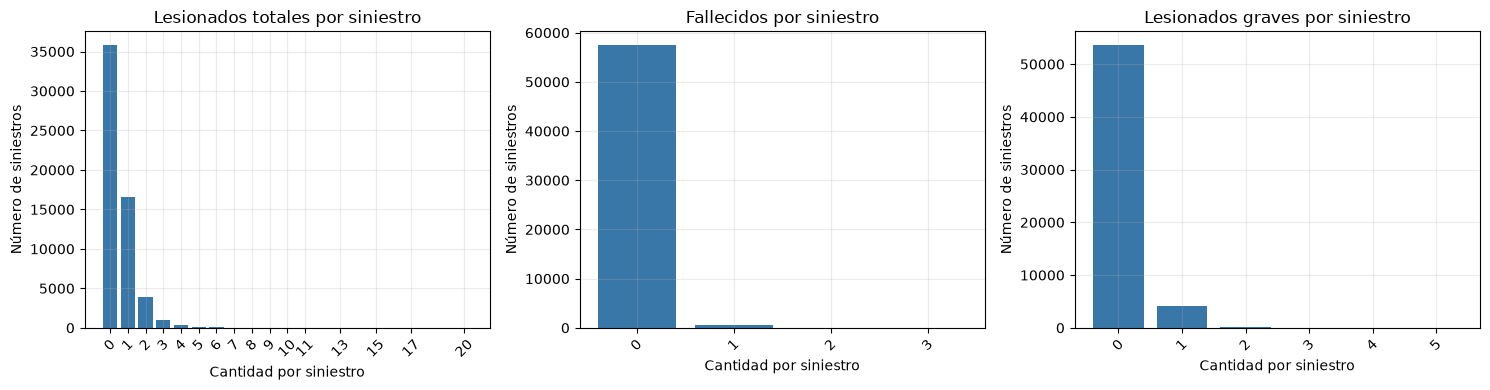

Frecuencia de lesionados totales (primeros valores):


,siniestros
TOTAL_LESI,
0,35772
1,16625
2,3956
3,961
4,363
5,126
6,54
7,21
8,10


In [ ]:
variables_distribucion = ['TOTAL_LESI', 'FALLECIDOS', 'GRAVES']
titulos = {
    'TOTAL_LESI': 'Lesionados totales por siniestro',
    'FALLECIDOS': 'Fallecidos por siniestro',
    'GRAVES': 'Lesionados graves por siniestro'
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, variables_distribucion):
    frecuencias = df[col].value_counts().sort_index()
    ax.bar(frecuencias.index.astype(int), frecuencias.values, color='#3977a8')
    ax.set_title(titulos[col])
    ax.set_xlabel('Cantidad por siniestro')
    ax.set_ylabel('Número de siniestros')
    ax.set_xticks(frecuencias.index)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print('Frecuencia de lesionados totales (primeros valores):')
display(df['TOTAL_LESI'].value_counts().sort_index().head(12).rename('siniestros').to_frame())

### Qué muestran las distribuciones

En las tres variables se acumulan muchos casos en cero y después quedan pocos siniestros con valores más altos. La distribución tiene una cola hacia la derecha. En TOTAL_LESI, el **61,8 %** no tiene lesionados; en FALLECIDOS, el **99,1 %** tiene cero fallecidos. Por eso, unos pocos casos grandes empujan la media hacia arriba.

El pico principal está en cero y luego las barras bajan; no se ven varios grupos separados. Como son conteos, que se repitan valores enteros pequeños es esperable y no basta para decir que hay un error de registro. Los valores altos sí convendría revisarlos: podrían ser siniestros graves reales. Como TOTAL_LESI se forma sumando las tres categorías de lesiones, tampoco lo voy a tratar como algo independiente de ellas.

### Actividad 1.2 — Media, mediana y sesgo

Para resumir los lesionados por siniestro comparo la media y la mediana. También miro el sesgo, porque la distribución tiene muchos ceros y algunos valores altos.

In [ ]:
resumen_principal = pd.Series({
    'media': df['TOTAL_LESI'].mean(),
    'mediana': df['TOTAL_LESI'].median(),
    'sesgo': df['TOTAL_LESI'].skew(),
    'proporcion_cero': (df['TOTAL_LESI'] == 0).mean()
})
display(resumen_principal.round(3).to_frame('valor'))

,valor
media,0.522
mediana,0.000
sesgo,2.885
proporcion_cero,0.618


### Qué medida usaría

La mediana de lesionados por siniestro es **0** y el promedio es cerca de **0,52**. Para hablar del siniestro típico, usaría la mediana: la mayoría no registra lesionados. Si quiero resumir cuántos lesionados hay en promedio por registro, mostraría también la media, aclarando que unos pocos siniestros con varios lesionados la elevan.

### Actividad 1.3 — Frecuencias categóricas

Reviso cuántos registros hay por día, tramo horario, zona, tipo y causa. Me fijo especialmente en las categorías con muy pocos casos.


Dia_semana:


,siniestros,porcentaje
Dia_semana,,
Viernes,9824,16.97
Jueves,8711,15.04
Miércoles,8578,14.81
Lunes,8391,14.49
Martes,8229,14.21
Sábado,7743,13.37
Domingo,6426,11.10



Tramo_horario:


,siniestros,porcentaje
Tramo_horario,,
Tarde (12–17),21493,37.12
Noche (18–23),18028,31.14
Mañana (06–11),14412,24.89
Madrugada (00–05),3969,6.85



ZONA:


,siniestros,porcentaje
ZONA,,
URBANA,56539,97.65
RURAL,1363,2.35



TIPO__CONA:


,siniestros,porcentaje
TIPO__CONA,,
COLISION,33272,57.46
CHOQUE,17407,30.06
ATROPELLO,4145,7.16
VOLCADURA,1883,3.25
OTRO TIPO,836,1.44
CAIDA,351,0.61
INCENDIO,8,0.01



CAUSA_NUEV:


,siniestros,porcentaje
CAUSA_NUEV,,
DISTRACCION DEL CONDUCTOR,20645,35.66
IMPRUDENCIA DEL CONDUCTOR,11316,19.54
DESOBEDIENCIA A SEÑALIZACION,7224,12.48
ALCOHOL EN CONDUCTOR,5064,8.75
CAUSAS NO DETERMINADAS,4436,7.66
VELOCIDAD IMPRUDENTE,3623,6.26
OTRAS CAUSAS,3386,5.85
IMPRUDENCIA DEL PEATON,965,1.67
FALLAS MECANICAS,508,0.88


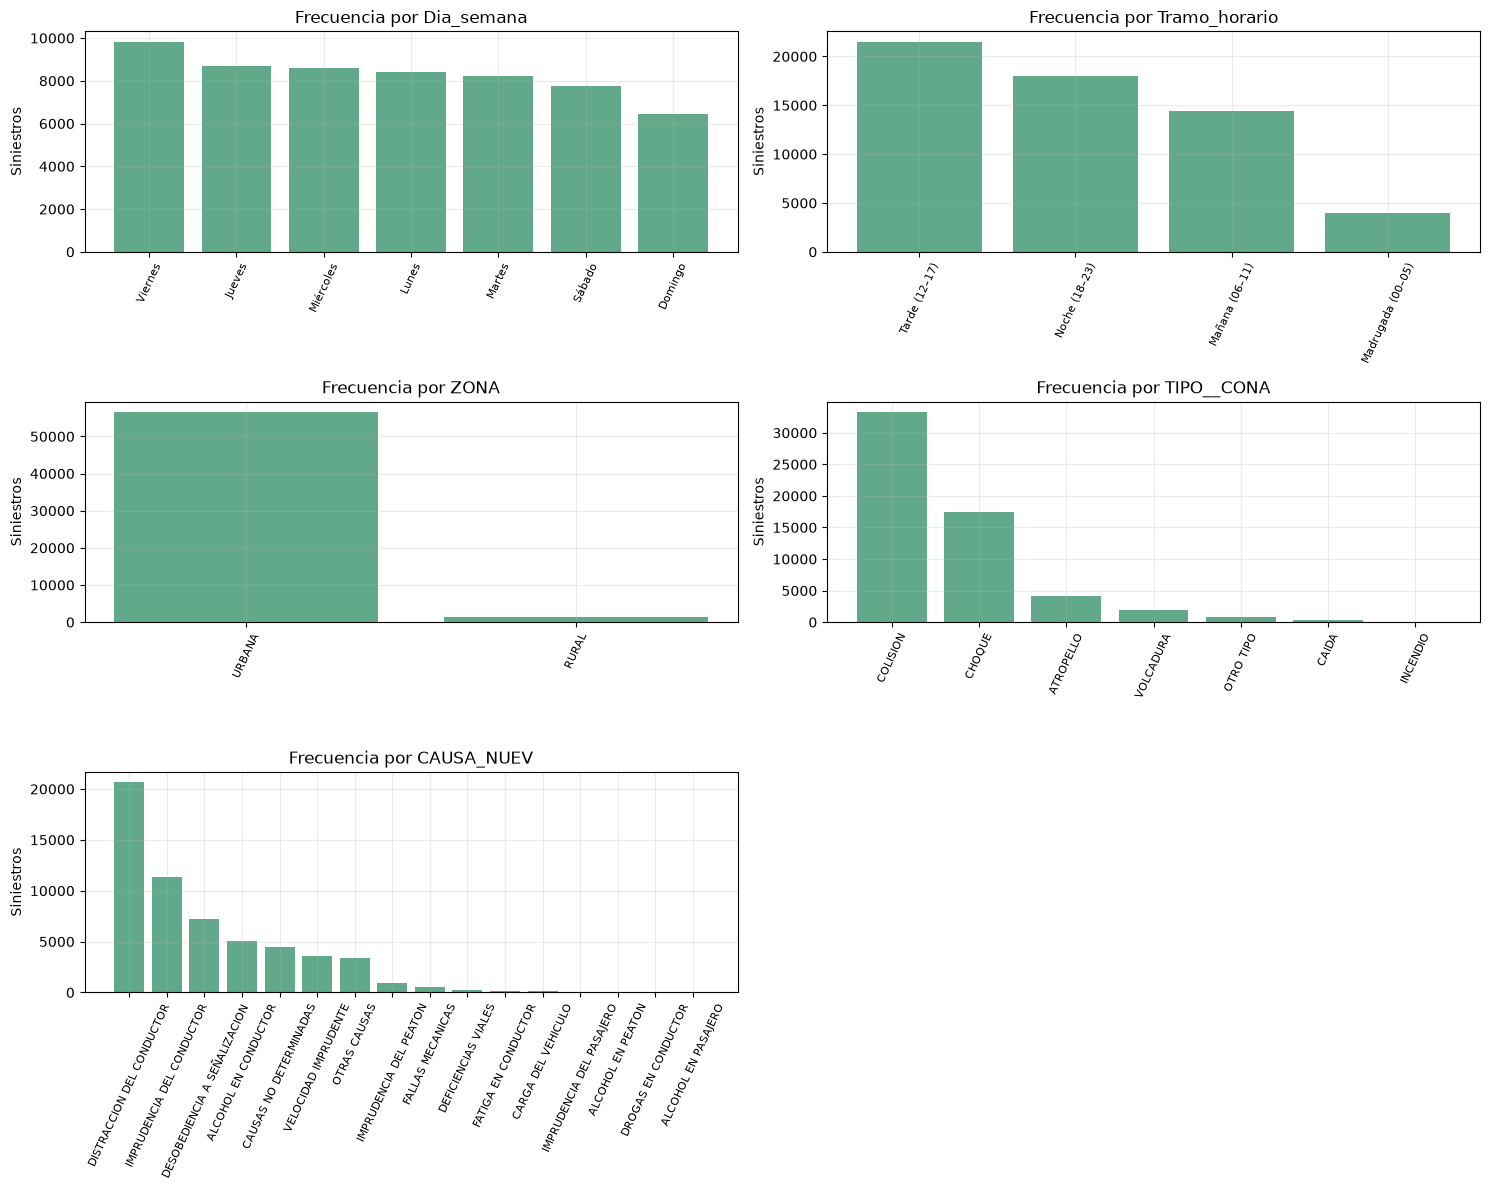

In [ ]:
# Celda de evidencia 1.3: frecuencias por categoría, incluido el tramo horario.
categoricas = ['Dia_semana', 'Tramo_horario', 'ZONA', 'TIPO__CONA', 'CAUSA_NUEV']
for col in categoricas:
    print(f'\n{col}:')
    tabla = df[col].value_counts(dropna=False).rename('siniestros').to_frame()
    tabla['porcentaje'] = (tabla['siniestros'] / len(df) * 100).round(2)
    display(tabla)

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for ax, col in zip(axes.flat, categoricas):
    frec = df[col].value_counts().sort_values(ascending=False)
    ax.bar(frec.index.astype(str), frec.values, color='#62a88a')
    ax.set_title(f'Frecuencia por {col}')
    ax.set_ylabel('Siniestros')
    ax.tick_params(axis='x', rotation=65, labelsize=8)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

### Qué muestran las categorías

La mayoría de los registros son de zonas urbanas y COLISION es el tipo general más común. En CAUSA_NUEV aparecen con más frecuencia DISTRACCION DEL CONDUCTOR (20.645 registros) e IMPRUDENCIA DEL CONDUCTOR (11.316). Más adelante reviso cuáles causas destacan dentro del tramo horario con más siniestros.

INCENDIO aparece solo **8 veces**, así que no sacaría conclusiones comparándolo con categorías mucho más grandes. Estos conteos indican cuántos siniestros quedaron registrados; para comparar riesgo necesitaríamos saber cuánto tránsito hubo en cada caso.

### Actividad 1.4 — Promedio diario por día de semana

Los totales por día de semana no son del todo comparables porque 2021 tuvo 53 viernes y 52 domingos. Por eso calculo también el promedio de siniestros por cada fecha.

In [ ]:
# Celda de evidencia 1.4: siniestros promedio por fecha según día de semana.
conteo_diario = df.groupby('FECHA').size().rename('siniestros').to_frame()
mapa_dias = {0:'Lunes', 1:'Martes', 2:'Miércoles', 3:'Jueves', 4:'Viernes', 5:'Sábado', 6:'Domingo'}
conteo_diario['dia_semana'] = conteo_diario.index.day_of_week.map(mapa_dias)
resumen_dias = conteo_diario.groupby('dia_semana').agg(
    fechas=('siniestros', 'size'),
    siniestros_totales=('siniestros', 'sum'),
    promedio_por_fecha=('siniestros', 'mean'),
    mediana_por_fecha=('siniestros', 'median')
).reindex(['Lunes','Martes','Miércoles','Jueves','Viernes','Sábado','Domingo'])
display(resumen_dias.round(2))

,fechas,siniestros_totales,promedio_por_fecha,mediana_por_fecha
dia_semana,,,,
Lunes,52,8391,161.37,165.0
Martes,52,8229,158.25,159.0
Miércoles,52,8578,164.96,166.5
Jueves,52,8711,167.52,171.5
Viernes,53,9824,185.36,184.0
Sábado,52,7743,148.90,144.5
Domingo,52,6426,123.58,121.5


### Qué se ve por día de semana

Hubo **185,36 siniestros por viernes**, en promedio, y **123,58 por domingo**. La diferencia sigue ahí al considerar cuántos viernes y domingos hubo en el año. Aun así, son registros, no una medida de riesgo: puede influir cuánta gente circula cada día.

---
## Parte 2 · Análisis bivariado y agrupación

### Actividad 2.1 — Lesionados por tramo horario

Ahora comparo los lesionados por siniestro entre los tramos horarios. Incluyo el número de casos para poner los promedios en contexto.

In [ ]:
# Celda de evidencia 2.1: comparación de lesionados por tramo horario.
comparacion_tramos = df.groupby('Tramo_horario', observed=True).agg(
    casos=('ID', 'size'),
    mediana_lesionados=('TOTAL_LESI', 'median'),
    promedio_lesionados=('TOTAL_LESI', 'mean'),
    desviacion_lesionados=('TOTAL_LESI', 'std'),
    proporcion_con_lesion=('TOTAL_LESI', lambda x: (x > 0).mean()),
    fallecidos_totales=('FALLECIDOS', 'sum')
).sort_values('promedio_lesionados', ascending=False)
comparacion_tramos['proporcion_con_lesion'] *= 100
display(comparacion_tramos.round(3))

,casos,mediana_lesionados,promedio_lesionados,desviacion_lesionados,proporcion_con_lesion,fallecidos_totales
Tramo_horario,,,,,,
Noche (18–23),18028,0.0,0.560,0.837,41.108,187
Madrugada (00–05),3969,0.0,0.543,0.859,38.322,91
Mañana (06–11),14412,0.0,0.527,0.836,39.092,105
Tarde (12–17),21493,0.0,0.483,0.817,35.193,131


### Qué se ve por tramo

La mediana es cero en todos los tramos. El promedio es un poco mayor en la noche (**0,56 lesionados por siniestro**) que en la tarde (**0,48**). Hay bastantes registros en ambos grupos: 18.028 en la noche y 21.493 en la tarde.

Esto muestra una diferencia en estos datos, pero no prueba que la hora la cause. También podría influir qué tipos de siniestro ocurren en cada tramo, dónde ocurren o cuántos vehículos circulan.

### Actividad 2.2 — Tipos y causas en el tramo con más registros

Identifico el tramo con más siniestros y, dentro de ese grupo, cuento los tipos y causas más frecuentes. Así respondo la segunda parte de la pregunta de la Entrega 1.

In [ ]:
# Celda de evidencia 2.2: tipos y causas en el tramo con más registros.
frecuencia_tramos = df['Tramo_horario'].value_counts()
tramo_mas_registros = frecuencia_tramos.idxmax()
df_tramo_mas_registros = df.loc[df['Tramo_horario'] == tramo_mas_registros]

print(f'Tramo con más registros: {tramo_mas_registros}')
print(f'Siniestros: {len(df_tramo_mas_registros):,} ({len(df_tramo_mas_registros) / len(df) * 100:.2f} % del conjunto)')
print('Tipos más frecuentes:')
display(df_tramo_mas_registros['TIPO__CONA'].value_counts().head(5).rename('siniestros').to_frame())
print('Causas más frecuentes:')
display(df_tramo_mas_registros['CAUSA_NUEV'].value_counts().head(5).rename('siniestros').to_frame())

Tramo con más registros: Tarde (12–17)
Siniestros: 21,493 (37.12 % del conjunto)
Tipos más frecuentes:


,siniestros
TIPO__CONA,
COLISION,13020
CHOQUE,6028
ATROPELLO,1508
VOLCADURA,493
OTRO TIPO,289


Causas más frecuentes:


,siniestros
CAUSA_NUEV,
DISTRACCION DEL CONDUCTOR,8443
IMPRUDENCIA DEL CONDUCTOR,4755
DESOBEDIENCIA A SEÑALIZACION,2763
CAUSAS NO DETERMINADAS,1634
OTRAS CAUSAS,1332


### Qué aparece en el tramo más frecuente

La tarde (12–17) reúne **21.493 siniestros**, el **37,12 %** del conjunto. Dentro de ese tramo, el tipo más común es **colisión** (13.020 registros). La causa más registrada es **distracción del conductor** (8.443), seguida de **imprudencia del conductor** (4.755).

Son las categorías más frecuentes en esta capa para ese tramo. No indican por sí solas por qué ocurrieron los siniestros ni cuál tramo tiene mayor riesgo.

### Actividad 2.3 — Matriz de correlación

Calculo la correlación entre los conteos de personas afectadas por siniestro. Dejo fuera el ID, el año y la hora codificada, porque no son cantidades comparables de la misma forma.

,TOTAL_LESI,FALLECIDOS,GRAVES,MENOS_GRAV,LEVES
TOTAL_LESI,1.000,0.010,0.332,0.283,0.903
FALLECIDOS,0.010,1.000,0.031,0.011,-0.004
GRAVES,0.332,0.031,1.000,-0.000,-0.017
MENOS_GRAV,0.283,0.011,-0.000,1.000,0.035
LEVES,0.903,-0.004,-0.017,0.035,1.000


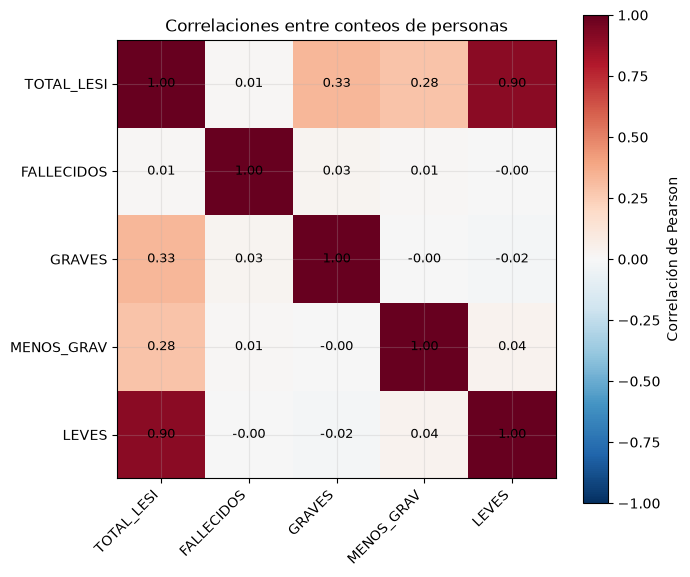

Par con mayor correlación absoluta: TOTAL_LESI y LEVES; r = 0.903


In [ ]:
vars_corr = ['TOTAL_LESI', 'FALLECIDOS', 'GRAVES', 'MENOS_GRAV', 'LEVES']
corr = df[vars_corr].corr()
display(corr.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(vars_corr)), labels=vars_corr, rotation=45, ha='right')
ax.set_yticks(range(len(vars_corr)), labels=vars_corr)
for i in range(len(vars_corr)):
    for j in range(len(vars_corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
plt.colorbar(im, ax=ax, label='Correlación de Pearson')
ax.set_title('Correlaciones entre conteos de personas')
plt.tight_layout()
plt.show()

tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
par_principal = tri.abs().idxmax()
x_col, y_col = par_principal
r_principal = corr.loc[x_col, y_col]
print(f'Par con mayor correlación absoluta: {x_col} y {y_col}; r = {r_principal:.3f}')

### Qué significa la correlación más alta

El par más correlacionado es TOTAL_LESI y LEVES (**r = 0,90**). Pero LEVES es parte del total, así que esta relación era esperable por cómo se construyó la variable. No la tomaría como un descubrimiento sobre una causa entre ambas.

### Actividad 2.4 — Revisar el par con mayor correlación

El gráfico muestra una muestra de 8.000 siniestros para que se pueda leer mejor la nube de puntos.

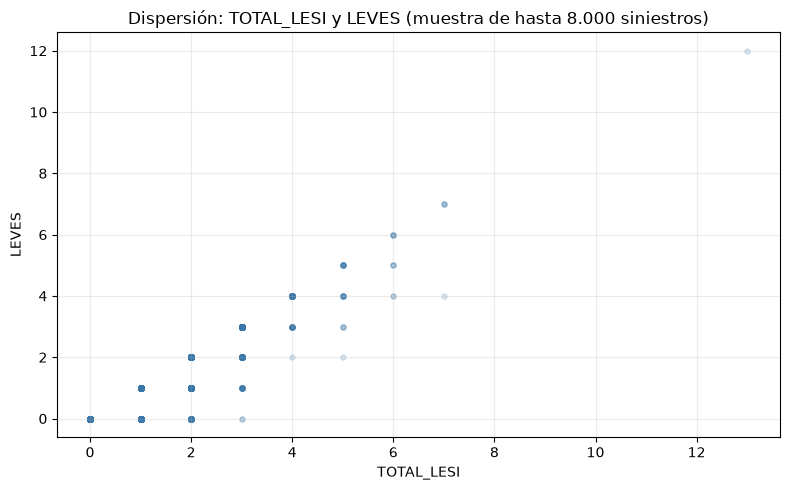

In [ ]:
muestra = df.sample(n=min(8000, len(df)), random_state=SEMILLA)
plt.figure(figsize=(8, 5))
plt.scatter(muestra[x_col], muestra[y_col], alpha=0.18, s=14, color='#3977a8')
plt.title(f'Dispersión: {x_col} y {y_col} (muestra de hasta 8.000 siniestros)')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.tight_layout()
plt.show()

### Qué muestra el gráfico y si hay que normalizar

Se ven muchos casos en cero y una tendencia hacia arriba. La explicación principal es que TOTAL_LESI incluye LEVES en su suma.

No hace falta normalizar por tamaño: cada fila ya es un siniestro, y las dos columnas son conteos por siniestro. En cambio, si comparáramos totales acumulados por semana o región, el tamaño del grupo sí afectaría el resultado. Para calcular riesgo también necesitaríamos el volumen de tránsito, que no viene en este archivo.

Para explorar si el tipo general de siniestro cambia la asociación, se calcula una correlación parcial lineal controlando `TIPO__CONA` con variables indicadoras. Luego se calcula la correlación dentro del grupo `COLISION`. Estos cálculos no eliminan la identidad matemática entre el total y sus componentes.

In [ ]:
def correlacion_parcial_categorica(datos, x, y, categoria):
    """Correlación de residuos tras ajustar x e y por una categoría nominal."""
    d = datos[[x, y, categoria]].dropna().copy()
    diseno = pd.get_dummies(d[categoria], drop_first=True, dtype=float)
    X = np.column_stack([np.ones(len(d)), diseno.to_numpy()])
    rx = d[x].to_numpy() - X @ np.linalg.lstsq(X, d[x].to_numpy(), rcond=None)[0]
    ry = d[y].to_numpy() - X @ np.linalg.lstsq(X, d[y].to_numpy(), rcond=None)[0]
    return np.corrcoef(rx, ry)[0, 1]

r_parcial_tipo = correlacion_parcial_categorica(df, x_col, y_col, 'TIPO__CONA')
datos_colision = df.loc[df['TIPO__CONA'] == 'COLISION', [x_col, y_col]].dropna()
r_colision = datos_colision[x_col].corr(datos_colision[y_col])
print('Correlación total:', round(r_principal, 3))
print('Correlación parcial controlando TIPO__CONA:', round(r_parcial_tipo, 3))
print('Correlación dentro de TIPO__CONA = COLISION:', round(r_colision, 3))
print('Casos dentro de COLISION:', len(datos_colision))

Correlación total: 0.903
Correlación parcial controlando TIPO__CONA: 0.902
Correlación dentro de TIPO__CONA = COLISION: 0.921
Casos dentro de COLISION: 33272


### Conclusión sobre este par

Al controlar por tipo general de siniestro, la correlación casi no cambia; dentro de las colisiones sigue siendo alta. Eso no convierte la relación en causal: TOTAL_LESI se calcula sumando LEVES y otras categorías. En este caso, la relación se explica sobre todo por esa suma, más que por un confundidor externo.

Lo tomo como una advertencia: el par con mayor correlación no siempre es el hallazgo más interesante.

---
## Parte 3 · Series temporales con frecuencia semanal

La pauta permite trabajar la variación en otra frecuencia si se indica. Aquí el resumen principal será semanal, de lunes a domingo. El primer y el último intervalo del archivo son semanas parciales; se marcan para no compararlos como si tuvieran siete días.

Para descomponer el patrón semanal de días se necesita conservar la serie diaria. Se usa período 7 para explorar diferencias que se repiten por día de la semana. Esto no evalúa estacionalidad anual.

Días en la serie: 365
Días sin registros: 0


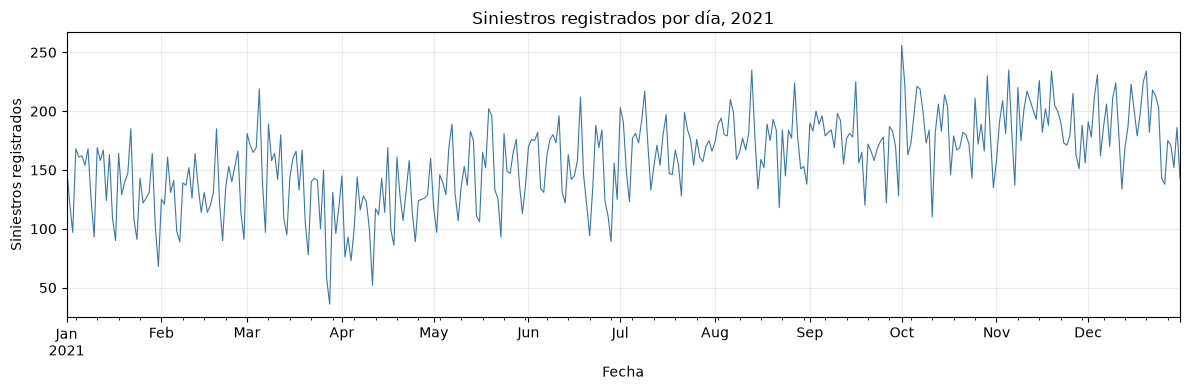

In [ ]:
# Recuento de siniestros para cada día del calendario.
serie_diaria = df.set_index('FECHA')['ID'].resample('D').count().asfreq('D', fill_value=0).rename('siniestros_diarios')
print('Días en la serie:', len(serie_diaria))
print('Días sin registros:', int((serie_diaria == 0).sum()))

ax = serie_diaria.plot(color='#3977a8', linewidth=0.8, figsize=(12, 4))
ax.set_title('Siniestros registrados por día, 2021')
ax.set_xlabel('Fecha')
ax.set_ylabel('Siniestros registrados')
plt.tight_layout()
plt.show()

### Qué muestra la serie diaria

La serie cuenta los siniestros registrados cada día; no muestra por sí sola si el tránsito fue más riesgoso. Hay datos para los 365 días de 2021. Las subidas y bajadas pueden relacionarse con el día de la semana, los feriados o la cantidad de personas que circula, entre otras cosas.

### Actividad 3.2 — Patrón de siete días

Descompongo la serie diaria con un período de 7 días para separar tendencia, patrón semanal y residuo.

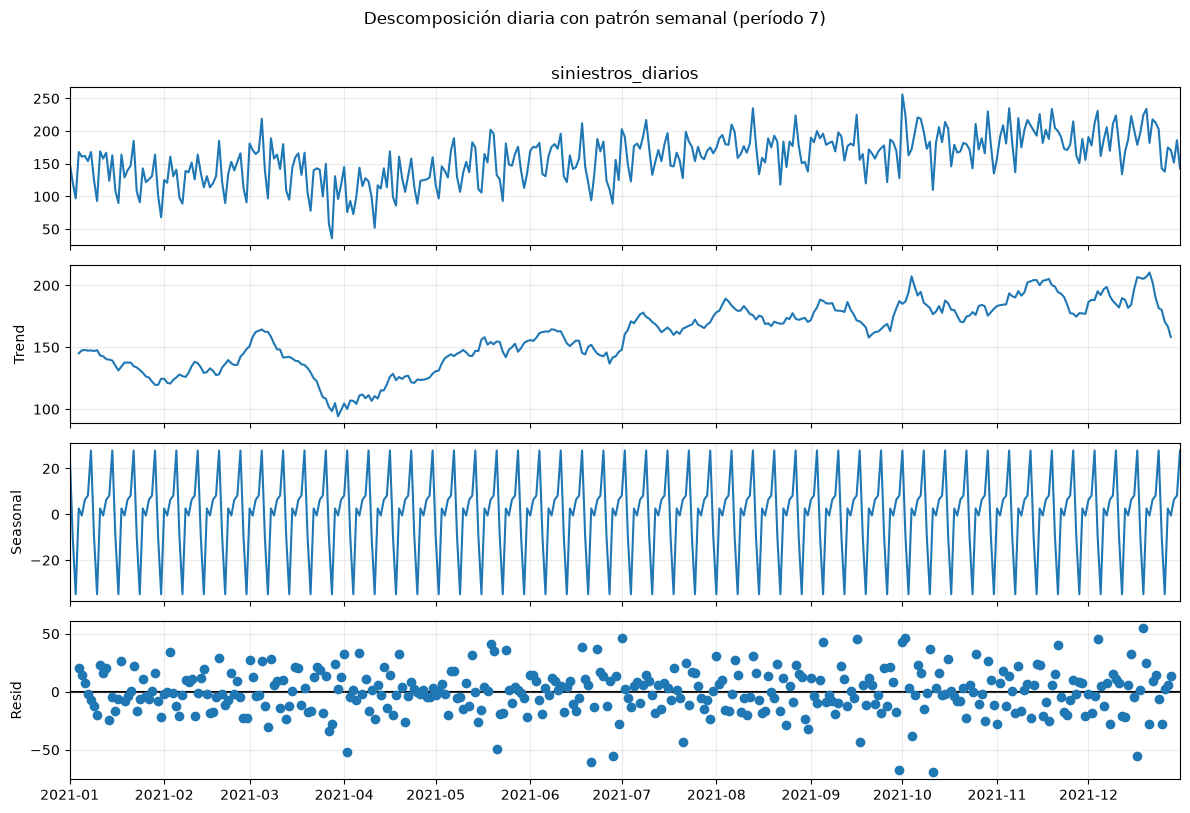

Tendencia media por mes:


,siniestros_diarios_tendencia
FECHA,
2021-01-01,136.3
2021-02-01,132.3
2021-03-01,135.2
2021-04-01,117.2
2021-05-01,147.1
2021-06-01,152.8
2021-07-01,167.3
2021-08-01,175.9
2021-09-01,175.2


Componente semanal medio por día:


,efecto_estimado
Lunes,2.6
Martes,-0.5
Miércoles,6.4
Jueves,8.2
Viernes,27.9
Sábado,-9.6
Domingo,-34.9


Cinco fechas con mayor residuo absoluto (signo conservado):


,residuo_firmado,residuo_absoluto
FECHA,,
2021-10-11,-69.28,69.28
2021-09-30,-67.48,67.48
2021-06-21,-60.56,60.56
2021-12-17,-55.58,55.58
2021-06-28,-55.28,55.28


Mayores residuos positivos:


,residuo
FECHA,
2021-12-19,54.596646
2021-07-01,46.803929
2021-10-02,46.577039


Mayores residuos negativos:


,residuo
FECHA,
2021-10-11,-69.275041
2021-09-30,-67.481785
2021-06-21,-60.560755


In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

descomposicion = seasonal_decompose(
    serie_diaria.astype(float),
    model='additive',
    period=7
)
fig = descomposicion.plot()
fig.set_size_inches(12, 8)
fig.suptitle('Descomposición diaria con patrón semanal (período 7)', y=1.01)
plt.tight_layout()
plt.show()

residuos = descomposicion.resid.dropna()
tendencia_mensual = descomposicion.trend.resample('MS').mean()
print('Tendencia media por mes:')
display(tendencia_mensual.round(1).rename('siniestros_diarios_tendencia').to_frame())

nombres_dias = {0:'Lunes', 1:'Martes', 2:'Miércoles', 3:'Jueves', 4:'Viernes', 5:'Sábado', 6:'Domingo'}
estacional_dia = descomposicion.seasonal.groupby(descomposicion.seasonal.index.day_of_week).mean()
estacional_dia.index = [nombres_dias[i] for i in estacional_dia.index]
print('Componente semanal medio por día:')
display(estacional_dia.round(1).rename('efecto_estimado').to_frame())

anomalias = residuos.loc[residuos.abs().nlargest(5).index].rename('residuo_firmado').to_frame()
anomalias['residuo_absoluto'] = anomalias['residuo_firmado'].abs()
print('Cinco fechas con mayor residuo absoluto (signo conservado):')
display(anomalias.sort_values('residuo_absoluto', ascending=False).round(2))
print('Mayores residuos positivos:')
display(residuos.nlargest(3).rename('residuo').to_frame())
print('Mayores residuos negativos:')
display(residuos.nsmallest(3).rename('residuo').to_frame())


### Qué muestran los componentes

La tendencia sube en general: pasa de **137,3 siniestros diarios en enero** a **191,5 en noviembre**, y baja a **185,4 en diciembre**. El patrón semanal estimado es más alto los viernes (**+27,2 respecto del nivel medio**) y más bajo los domingos (**−35,1**). Esto describe los registros de 2021; no es una tasa de riesgo.

Los residuos más negativos aparecen el **11 de octubre (−69,38)**, el **30 de septiembre (−68,27)** y el **21 de junio (−60,67)**. En esos días hubo menos siniestros de lo que estiman la tendencia y el patrón semanal. Las dejaría como fechas para revisar: con este análisis no puedo saber si fueron errores de registro o eventos reales. Con un solo año no puedo comprobar si este patrón se repite en otros años.

### Actividad 3.3 — Cambio de una semana a la siguiente

Agrupo los datos de lunes a domingo y calculo cuánto sube o baja el número de siniestros respecto de la semana anterior. Este es el contraste semanal indicado para el trabajo; no una comparación con el mismo período del año anterior.

Intervalos semanales: 53
Semanas completas: 51
Semanas parciales al inicio/final: 2


,siniestros,lesionados,dias_observados,semana_completa,cambio_siniestros_vs_semana_anterior_pct
SEMANA_INICIO,,,,,
2020-12-28,371,219,3,False,NaN
2021-01-04,1031,584,7,True,NaN
2021-01-11,980,488,7,True,-4.95
2021-12-13,1382,660,7,True,5.34
2021-12-20,1331,674,7,True,-3.69
2021-12-27,827,413,5,False,NaN


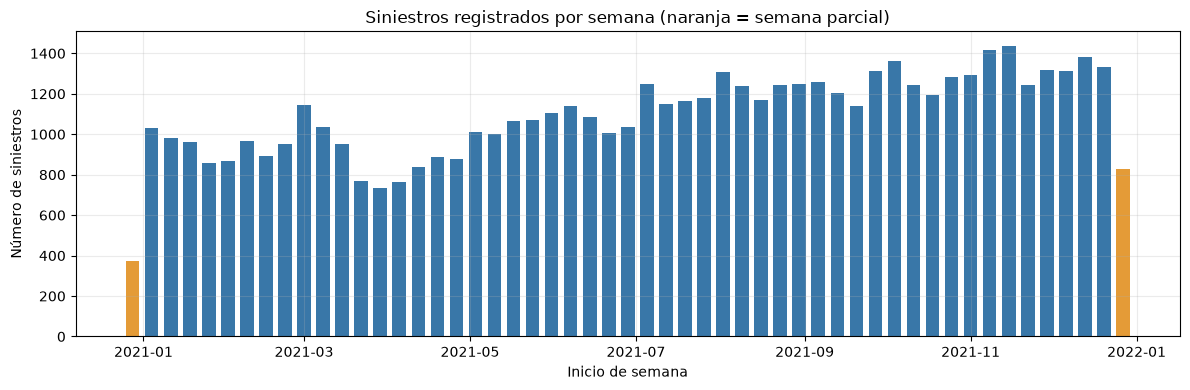

Semanas completas con mayor cantidad de siniestros:


,siniestros,lesionados
SEMANA_INICIO,,
2021-11-15,1437,761
2021-11-08,1417,774
2021-12-13,1382,660
2021-10-04,1364,673
2021-12-20,1331,674


Semanas completas con menor cantidad de siniestros:


,siniestros,lesionados
SEMANA_INICIO,,
2021-03-29,732,402
2021-04-05,762,422
2021-03-22,768,417
2021-04-12,840,449
2021-01-25,856,465


Mayor aumento entre semanas completas: 20.27 % en la semana que inicia 2021-07-05
Mayor disminución entre semanas completas: -19.5 % en la semana que inicia 2021-03-22


In [ ]:
df['SEMANA_INICIO'] = df['FECHA'] - pd.to_timedelta(df['FECHA'].dt.day_of_week, unit='D')
semanal = df.groupby('SEMANA_INICIO').agg(
    siniestros=('ID', 'size'),
    lesionados=('TOTAL_LESI', 'sum'),
    dias_observados=('FECHA', 'nunique')
).sort_index()
semanal['semana_completa'] = semanal['dias_observados'].eq(7)
semanal['cambio_siniestros_vs_semana_anterior_pct'] = semanal['siniestros'].pct_change(fill_method=None) * 100
semana_previa_completa = semanal['semana_completa'].shift(1, fill_value=False)
semanal.loc[~(semanal['semana_completa'] & semana_previa_completa),
            'cambio_siniestros_vs_semana_anterior_pct'] = np.nan
print('Intervalos semanales:', len(semanal))
print('Semanas completas:', int(semanal['semana_completa'].sum()))
print('Semanas parciales al inicio/final:', int((~semanal['semana_completa']).sum()))
display(pd.concat([semanal.head(3), semanal.tail(3)]).round(2))

fig, ax = plt.subplots(figsize=(12, 4))
colores = np.where(semanal['semana_completa'], '#3977a8', '#e49b37')
ax.bar(semanal.index, semanal['siniestros'], width=5, color=colores)
ax.set_title('Siniestros registrados por semana (naranja = semana parcial)')
ax.set_xlabel('Inicio de semana')
ax.set_ylabel('Número de siniestros')
plt.tight_layout()
plt.show()

print('Semanas completas con mayor cantidad de siniestros:')
display(semanal.loc[semanal['semana_completa']].nlargest(5, 'siniestros')[['siniestros', 'lesionados']])
print('Semanas completas con menor cantidad de siniestros:')
display(semanal.loc[semanal['semana_completa']].nsmallest(5, 'siniestros')[['siniestros', 'lesionados']])
variaciones_validas = semanal['cambio_siniestros_vs_semana_anterior_pct'].dropna()
print('Mayor aumento entre semanas completas:', round(variaciones_validas.max(), 2), '% en la semana que inicia', variaciones_validas.idxmax().date())
print('Mayor disminución entre semanas completas:', round(variaciones_validas.min(), 2), '% en la semana que inicia', variaciones_validas.idxmin().date())


### Qué se ve al comparar semanas

Entre las semanas completas, la que empezó el **15 de noviembre** tuvo más siniestros (**1.437**) y la que empezó el **29 de marzo** tuvo menos (**732**). La mayor subida respecto de la semana anterior fue **20,27 %** en la semana del 5 de julio; la mayor bajada fue **−19,50 %** en la semana del 22 de marzo.

Las semanas incompletas del inicio y final del año están marcadas en naranjo y no entran en esos cambios porcentuales. Son variaciones en el número de registros, no en una tasa de riesgo. Como el archivo solo tiene 2021, no se puede calcular el cambio frente a la misma semana de otro año.

---
## Parte 4 · Hipótesis de trabajo

Las hipótesis siguientes son afirmaciones exploratorias, falsables y derivadas de las tablas anteriores. No se interpretan como resultados causales.

### Hipótesis 1 — Frecuencia por tramo horario

- **Afirmación:** la tarde (12–17) tiene más siniestros registrados que los otros tramos durante 2021.
- **Evidencia:** la tabla de la celda de código **Actividad 1.3** muestra los conteos y porcentajes por tramo; la tarde aparece primero.
- **Qué la refutaría:** que al revisar los registros válidos otro tramo tenga un conteo igual o mayor.
- **Qué podría confundir la interpretación:** el volumen de tránsito puede ser distinto entre tramos. El conjunto no trae ese dato, así que hablo de frecuencia registrada, no de riesgo.

### Hipótesis 2 — Tipo y causa más frecuentes en el tramo de mayor frecuencia

- **Afirmación:** dentro de la tarde (12–17), colisión es el tipo más registrado y distracción del conductor es la causa más registrada.
- **Evidencia:** la celda de código **Actividad 2.2** cuenta tipos y causas dentro del tramo con más siniestros.
- **Qué la refutaría:** que, al volver a contar las categorías de ese tramo, otro tipo o causa aparezca más veces.
- **Qué podría confundir la interpretación:** las categorías dependen de cómo se clasificaron los siniestros y de qué comunas o regiones aportan más registros.

---
## Parte 5 · Cierre y versionado

Agrego SEMANA_INICIO, que marca el lunes de cada semana, y guardo una copia del conjunto explorado.

In [ ]:
df.to_csv('mi_conjunto_explorado_2021.csv', index=False, encoding='utf-8-sig')
print('Archivo guardado: mi_conjunto_explorado_2021.csv')
print('Dimensiones guardadas:', df.shape)

Archivo guardado: mi_conjunto_explorado_2021.csv
Dimensiones guardadas: (57902, 23)


## Cierre

En 2021, la tarde fue el tramo con más registros. Dentro de ese tramo, colisión fue el tipo más común y distracción del conductor, la causa más frecuente. También observé diferencias en lesionados por tramo y en los conteos semanales, pero estos datos describen registros: sin volumen de tránsito no permiten comparar riesgo.

**Repositorio público:** [Cienciadedatos — rama Sumativa2](https://github.com/fre-caneo/Cienciadedatos/tree/Sumativa2)